In [1]:
import numpy as np, pandas as pd
rng = np.random.default_rng(42)

tx = pd.DataFrame({
    "customer_id": rng.integers(0, 500, 20000),
    "amount": np.round(rng.lognormal(4.5, 1.0, 20000), 2),
})
print(tx.head())
print(len(tx), "transakcji")

   customer_id  amount
0           44   13.69
1          386  278.80
2          327  293.75
3          219   56.02
4          216  151.60
20000 transakcji


In [2]:
tx["timestamp"] = pd.Timestamp("2026-01-01") + pd.to_timedelta(rng.integers(0, 90*24*3600, len(tx)), unit="s")
tx["is_suspicious"] = False

# 25 klientów, którzy robią structuring
sus_customers = rng.choice(500, 25, replace=False)
rows = []
for cid in sus_customers:
    start = pd.Timestamp("2026-01-01") + pd.to_timedelta(int(rng.integers(0, 80)), unit="D")
    for k in range(int(rng.integers(5, 9))):
        rows.append((cid, round(float(rng.uniform(9000, 9900)), 2), start + pd.to_timedelta(k*6, unit="h"), True))

sus = pd.DataFrame(rows, columns=["customer_id", "amount", "timestamp", "is_suspicious"])
tx = pd.concat([tx, sus], ignore_index=True).sort_values("timestamp")

print(tx.is_suspicious.value_counts())

is_suspicious
False    20000
True       153
Name: count, dtype: int64


In [3]:
# legalne duże faktury tuż pod progiem -> źródło false positives
normal_idx = tx.index[~tx.is_suspicious]
chosen = rng.choice(normal_idx, 1500, replace=False)
tx.loc[chosen, "amount"] = np.round(rng.uniform(9000, 9990, 1500), 2)
tx.loc[chosen, "customer_id"] = rng.integers(0, 60, 1500)

print(((tx.amount >= 9000) & (tx.amount < 10000)).sum(), "transakcji w przedziale 9000-10000")

1653 transakcji w przedziale 9000-10000


In [4]:
def structuring_alerts(tx, low=9000, high=10000, min_count=3, window="48h"):
    near = tx[(tx.amount >= low) & (tx.amount < high)].set_index("timestamp").sort_index()
    cnt = near.groupby("customer_id")["amount"].rolling(window).count()
    return set(cnt[cnt >= min_count].index.get_level_values(0))

# prawda: kto naprawdę jest podejrzany (znamy, bo sami wstrzyknęliśmy)
truth = set(tx[tx.is_suspicious].customer_id)

In [5]:
results = []
for m in [2, 3, 4, 5, 6, 7]:
    a = structuring_alerts(tx, min_count=m)
    tp = len(a & truth); fp = len(a - truth)
    results.append({"prog": m, "alerty": len(a), "TP": tp, "FP": fp,
                    "precision": round(tp/max(len(a),1), 2), "recall": round(tp/len(truth), 2)})
res = pd.DataFrame(results)
res

,prog,alerty,TP,FP,precision,recall
0,2,82,25,57,0.30,1.00
1,3,71,25,46,0.35,1.00
2,4,38,25,13,0.66,1.00
3,5,26,25,1,0.96,1.00
4,6,16,16,0,1.00,0.64
5,7,8,8,0,1.00,0.32


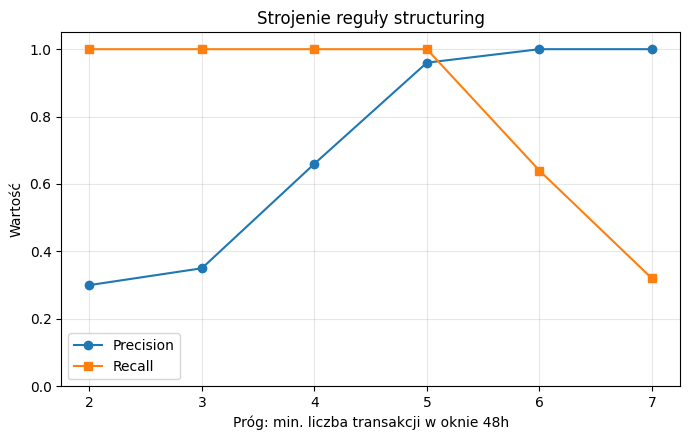

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(res.prog, res.precision, marker="o", label="Precision")
ax.plot(res.prog, res.recall, marker="s", label="Recall")
ax.set_xlabel("Próg: min. liczba transakcji w oknie 48h"); ax.set_ylabel("Wartość"); ax.set_ylim(0, 1.05)
ax.set_title("Strojenie reguły structuring"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig("results.png", dpi=150)
plt.show()